# Customer Churn Prediction — Model Training & Evaluation

## 1. Introduction

This notebook trains and evaluates three classification models for customer churn, using the
leakage-safe preprocessing architecture already built and tested in
`02_data_preprocessing.ipynb` / `src/data_preprocessing.py`. That architecture is **reused, not
redesigned**.

**The workflow enforced here:**

```
raw data -> clean_data() -> X/y separation -> stratified train/test split
   -> [per model] preprocessing -> SMOTE -> classifier
   -> stratified 5-fold CV on TRAINING data only        (model comparison)
   -> hyperparameter search on TRAINING data only       (tuning)
   -> threshold selection from out-of-fold TRAINING preds (threshold choice)
   -> ONE final evaluation on the sealed test set        (unbiased estimate)
```

**What the test set is never used for:** fitting preprocessing, SMOTE resampling,
cross-validation, hyperparameter tuning, or threshold selection. It is touched exactly once, at
the end, to produce the reported generalization estimate.

**Model selection criterion, declared up front (before seeing any results):** the final model is
whichever achieves the **highest mean ROC-AUC across stratified 5-fold cross-validation on the
training set**. ROC-AUC is chosen because it is threshold-independent and robust to the class
imbalance in this dataset, unlike accuracy — with ~26.5% churn, a model predicting "no churn" for
everyone would score ~73.5% accuracy while being useless. Declaring the criterion in advance
prevents cherry-picking a winner after the fact.

All metrics in this notebook are computed from actual model predictions. Nothing is hardcoded.

## 2. Imports

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

import data_preprocessing as dp
import evaluate as ev

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Telco-Customer-Churn.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_SPLITS = 5

print("Project root:", PROJECT_ROOT)


Project root: /path/to/customer-churn-prediction


In [2]:
# Record exact package versions for reproducibility
import sklearn, imblearn, xgboost, matplotlib
for lib in [pd, np, sklearn, imblearn, xgboost, matplotlib, sns, joblib]:
    print(f"{lib.__name__:<14} {lib.__version__}")


pandas         3.0.2
numpy          2.4.4
sklearn        1.8.0
imblearn       0.14.2
xgboost        3.4.1
matplotlib     3.10.8
seaborn        0.13.2
joblib         1.5.3


## 3. Load and Prepare Data

We reuse `dp.load_data()` and `dp.clean_data()` exactly as validated in Notebook 2.

In [3]:
raw_df = dp.load_data(RAW_DATA_PATH)
df_clean = dp.clean_data(raw_df)
X, y = dp.split_features_target(df_clean)

print(f"Raw shape:     {raw_df.shape}")
print(f"Cleaned shape: {df_clean.shape}")
print(f"X shape: {X.shape}, y shape: {y.shape}")
print(f"Target distribution:\n{y.value_counts()}")
print(f"Churn rate: {y.mean():.4f}")


Raw shape:     (7043, 21)
Cleaned shape: (7043, 20)
X shape: (7043, 19), y shape: (7043,)
Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64
Churn rate: 0.2654


## 4. Train/Test Split

Stratified 80/20 split with `random_state=42`. **From this cell onward, `X_test`/`y_test` are
sealed** — they are not referenced again until Section 12.

In [4]:
X_train, X_test, y_train, y_test = dp.create_train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
numerical_features, categorical_features = dp.get_feature_types(X_train)

print(f"X_train: {X_train.shape}  churn rate: {y_train.mean():.4f}")
print(f"X_test:  {X_test.shape}  churn rate: {y_test.mean():.4f}")
print(f"\nTrain class counts:\n{y_train.value_counts()}")
print(f"\nTest class counts:\n{y_test.value_counts()}")
print(f"\nNumerical features ({len(numerical_features)}): {numerical_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")


X_train: (5634, 19)  churn rate: 0.2654
X_test:  (1409, 19)  churn rate: 0.2654

Train class counts:
Churn
0    4139
1    1495
Name: count, dtype: int64

Test class counts:
Churn
0    1035
1     374
Name: count, dtype: int64

Numerical features (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 5. Build Model Pipelines

Each model gets its own `imblearn` pipeline with an identical architecture and identical training
data — the only difference between them is the final classifier. This makes the comparison fair.

Using `imblearn.pipeline.Pipeline` is what guarantees SMOTE runs **only** during `.fit()` on
training data and is automatically skipped during `.predict()` / `.transform()`.

In [5]:
baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,            # high enough for reliable convergence on scaled features
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=2,
        n_jobs=-1, random_state=RANDOM_STATE,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9,
        eval_metric="logloss", random_state=RANDOM_STATE,
    ),
}

pipelines = {
    name: dp.build_pipeline(
        preprocessor=dp.build_preprocessor(numerical_features, categorical_features),
        classifier=model, use_smote=True, random_state=RANDOM_STATE,
    )
    for name, model in baseline_models.items()
}

for name, pipe in pipelines.items():
    print(f"{name}: {[step_name for step_name, _ in pipe.steps]}")


Logistic Regression: ['preprocessor', 'smote', 'classifier']
Random Forest: ['preprocessor', 'smote', 'classifier']
XGBoost: ['preprocessor', 'smote', 'classifier']


## 6. Logistic Regression

A linear model that estimates the log-odds of churn as a weighted sum of the features. Its main
strength is **interpretability**: each coefficient has a direct, explainable meaning, which matters
in a business setting where a retention team needs to understand *why* a customer was flagged.
`max_iter=2000` ensures reliable convergence on the scaled feature set.

In [6]:
lr_pipeline = pipelines["Logistic Regression"]
lr_pipeline


,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The

## 7. Random Forest

An ensemble of decision trees trained on bootstrapped samples with random feature subsets. It
captures **non-linear relationships and feature interactions** automatically and is robust to
outliers and unscaled features. Parameters here are deliberately moderate (`n_estimators=300`,
`max_depth=12`) rather than needlessly large — this dataset has ~5.6k training rows, so a heavier
configuration would cost compute without a meaningful benefit.

In [7]:
rf_pipeline = pipelines["Random Forest"]
rf_pipeline


,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The

## 8. XGBoost

Gradient boosting builds trees sequentially, each correcting the errors of the previous ones. It
is typically strong on tabular data, at the cost of more hyperparameters and lower direct
interpretability (which is why SHAP matters in Step 5). The baseline configuration below is
sensible rather than aggressive. Note we set `eval_metric="logloss"` explicitly, which is the
correct configuration for the installed XGBoost version.

In [8]:
xgb_pipeline = pipelines["XGBoost"]
print("XGBoost version in use:", xgboost.__version__)
xgb_pipeline


XGBoost version in use: 3.4.1


,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The

## 9. Cross-Validation

We run stratified 5-fold cross-validation (`shuffle=True`, `random_state=42`) on the **training
data only**.

### Why SMOTE must live inside the CV pipeline

Because we pass the *entire pipeline* to `cross_validate`, scikit-learn refits every step within
each fold:

```
for each fold:
    training fold  -> preprocessing.fit_transform -> SMOTE resample -> model.fit
    validation fold -> preprocessing.transform    -> (SMOTE skipped) -> model.predict
```

If instead we had applied SMOTE once to all of `X_train` *before* cross-validating, synthetic
minority samples would be generated using information from rows that later land in the validation
fold. Worse, near-duplicate synthetic copies of a validation row could end up in the training fold
— the model would effectively have seen the answer. The reported CV score would then be
optimistically biased and useless for choosing between models. Keeping SMOTE inside the pipeline
makes that structurally impossible.

In [9]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

baseline_cv_results = []
for name, pipeline in pipelines.items():
    print(f"Cross-validating {name}...")
    result = ev.cross_validate_model(
        pipeline, X_train, y_train,
        n_splits=N_SPLITS, random_state=RANDOM_STATE, model_name=name,
    )
    baseline_cv_results.append(result)

baseline_cv_df = ev.compare_models(baseline_cv_results)
print("\nDone.")


Cross-validating Logistic Regression...


Cross-validating Random Forest...


Cross-validating XGBoost...



Done.


In [10]:
# Baseline CV summary table (mean +/- std across the 5 folds)
display_cols = ["model"] + [f"{m}_{s}" for m in ["accuracy","precision","recall","f1","roc_auc"] for s in ["mean","std"]]
baseline_cv_df[display_cols].round(4)


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression,0.7567,0.0130,0.5279,0.0170,0.7873,0.0373,0.6318,0.0212,0.8450,0.0131
1,Random Forest,0.7840,0.0104,0.5819,0.0186,0.6622,0.0233,0.6193,0.0181,0.8386,0.0082
2,XGBoost,0.7911,0.0095,0.6136,0.0241,0.5779,0.0162,0.5949,0.0142,0.8319,0.0076


## 10. Baseline Comparison

Below, the mean CV scores are visualized with standard-deviation error bars. The error bars
matter: if two models' means differ by less than their fold-to-fold variation, that difference is
not meaningful evidence that one is better.

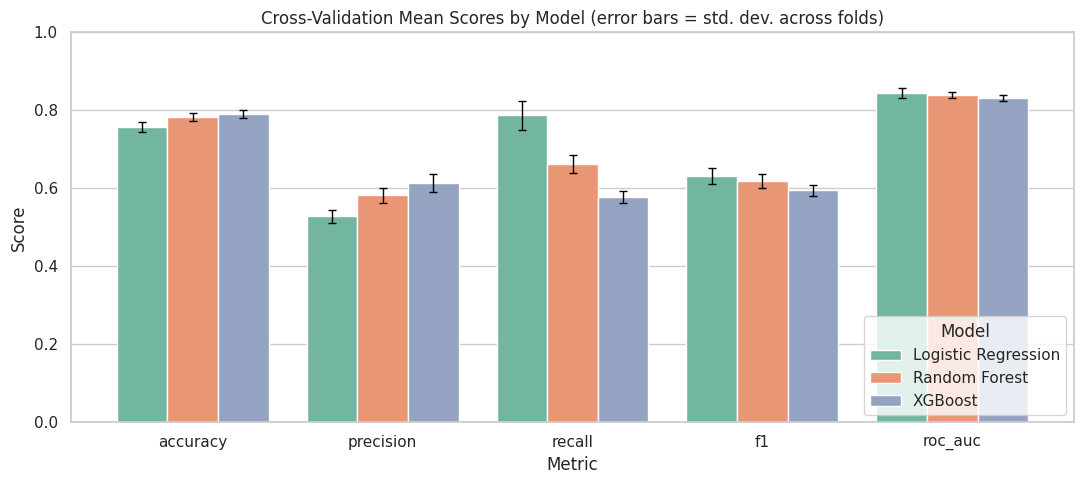

In [11]:
fig = ev.plot_cv_comparison(baseline_cv_df, save_path=FIGURES_DIR / "cv_comparison_baseline.png")
plt.show()


## 11. Hyperparameter Tuning

We tune with `RandomizedSearchCV`, scoring on `roc_auc`, using the same `StratifiedKFold`.

**Critically, the entire pipeline is passed to the search** (note the `classifier__` prefixes in
the parameter grids). This means every candidate configuration is refit with preprocessing and
SMOTE applied *inside* each CV fold — the search cannot leak information either. `X_test` is not
involved at any point.

The search is kept deliberately modest (`n_iter` capped at 10, capped further to the grid size
where the grid is smaller). Tuning aggressively to squeeze out a slightly higher number risks
overfitting the cross-validation procedure itself.

In [12]:
def get_param_distributions(model_name):
    if model_name == "Logistic Regression":
        # scikit-learn 1.8 deprecated the explicit `penalty` parameter, so we
        # tune only C (regularisation strength) - the parameter that matters here.
        return {"classifier__C": [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0]}
    if model_name == "Random Forest":
        return {
            "classifier__n_estimators": [200, 300, 500],
            "classifier__max_depth": [8, 12, 16, None],
            "classifier__min_samples_leaf": [1, 2, 4],
            "classifier__max_features": ["sqrt", "log2"],
        }
    if model_name == "XGBoost":
        return {
            "classifier__n_estimators": [200, 300, 500],
            "classifier__max_depth": [3, 4, 5, 6],
            "classifier__learning_rate": [0.03, 0.05, 0.1, 0.2],
            "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
            "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
        }
    raise ValueError(model_name)

tuned_pipelines = {}
best_params_per_model = {}

for name, pipeline in pipelines.items():
    param_dist = get_param_distributions(name)
    total_combos = int(np.prod([len(v) for v in param_dist.values()]))
    n_iter = min(10, total_combos)

    print(f"Tuning {name} (n_iter={n_iter} of {total_combos} combinations)...")
    search = RandomizedSearchCV(
        estimator=pipeline, param_distributions=param_dist, n_iter=n_iter,
        scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True,
    )
    search.fit(X_train, y_train)
    tuned_pipelines[name] = search.best_estimator_
    best_params_per_model[name] = search.best_params_
    print(f"   best CV ROC-AUC: {search.best_score_:.4f}")
    print(f"   best params: {search.best_params_}")


Tuning Logistic Regression (n_iter=8 of 8 combinations)...


   best CV ROC-AUC: 0.8451
   best params: {'classifier__C': 10.0}
Tuning Random Forest (n_iter=10 of 72 combinations)...


   best CV ROC-AUC: 0.8433
   best params: {'classifier__n_estimators': 300, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': 8}
Tuning XGBoost (n_iter=10 of 768 combinations)...


   best CV ROC-AUC: 0.8470
   best params: {'classifier__subsample': 0.7, 'classifier__n_estimators': 200, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.8}


In [13]:
# Re-run the full metric suite on the tuned pipelines, same CV protocol
tuned_cv_results = []
for name, tuned in tuned_pipelines.items():
    print(f"Cross-validating tuned {name}...")
    tuned_cv_results.append(ev.cross_validate_model(
        tuned, X_train, y_train,
        n_splits=N_SPLITS, random_state=RANDOM_STATE, model_name=name,
    ))

tuned_cv_df = ev.compare_models(tuned_cv_results)
tuned_cv_df[display_cols].round(4)


Cross-validating tuned Logistic Regression...


Cross-validating tuned Random Forest...


Cross-validating tuned XGBoost...


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression,0.7556,0.0145,0.5265,0.0187,0.7860,0.0366,0.6304,0.0232,0.8451,0.0133
1,Random Forest,0.7774,0.0101,0.5626,0.0165,0.7284,0.0238,0.6346,0.0151,0.8433,0.0086
2,XGBoost,0.7934,0.0086,0.5954,0.0146,0.6916,0.0231,0.6398,0.0157,0.8470,0.0102


In [14]:
# Did tuning actually help? Compare baseline vs tuned CV ROC-AUC per model.
comparison_rows = []
for base, tuned in zip(baseline_cv_results, tuned_cv_results):
    comparison_rows.append({
        "model": base["model"],
        "baseline_cv_roc_auc": round(base["roc_auc_mean"], 4),
        "tuned_cv_roc_auc": round(tuned["roc_auc_mean"], 4),
        "change": round(tuned["roc_auc_mean"] - base["roc_auc_mean"], 4),
    })
tuning_effect_df = pd.DataFrame(comparison_rows)
tuning_effect_df


,model,baseline_cv_roc_auc,tuned_cv_roc_auc,change
0,Logistic Regression,0.8450,0.8451,0.0001
1,Random Forest,0.8386,0.8433,0.0048
2,XGBoost,0.8319,0.8470,0.0151


## 12. Final Test Evaluation

Now — and only now — we touch the test set. Each tuned pipeline is fit on the full training data
and evaluated **once** on `X_test`.

**Why the test set is reserved for this single use:** every time a dataset influences a decision
(which features to use, which model to pick, which hyperparameters, which threshold), the model
becomes a little more tailored to it. A test set used for any of those decisions stops being an
unbiased sample of "new, unseen customers" and starts flattering the model. Because all of our
decisions above were made using cross-validation on the training data, the test score below is an
honest estimate of performance on genuinely new data.

In [15]:
test_results = []
model_probas = {}

for name, tuned in tuned_pipelines.items():
    tuned.fit(X_train, y_train)                 # fit on full training data
    y_pred = tuned.predict(X_test)              # first and only use of X_test
    y_proba = tuned.predict_proba(X_test)[:, 1]
    model_probas[name] = (y_test.values, y_proba)
    test_results.append(ev.calculate_classification_metrics(y_test, y_pred, y_proba, model_name=name))

test_df = ev.compare_models(test_results)
test_df.round(4)


,model,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
0,Logistic Regression,0.7367,0.5025,0.7941,0.6155,0.8394,741,294,77,297
1,Random Forest,0.7637,0.5416,0.7139,0.6159,0.8372,809,226,107,267
2,XGBoost,0.7736,0.5599,0.6872,0.6170,0.8427,833,202,117,257


### Interpreting the trade-offs in a churn context

- **Recall** (of the churners, how many did we catch?) — a false negative is a customer who churns
  without ever being flagged, so the retention team never got a chance to intervene. That is
  usually the costly error.
- **Precision** (of those we flagged, how many actually churned?) — a false positive means
  spending a retention offer/discount on someone who would have stayed anyway. Wasteful, but
  usually far cheaper than losing a customer.
- **F1** balances the two, useful when you need a single number but care about both.
- **ROC-AUC** measures ranking quality across *all* thresholds, independent of where you draw the
  0/1 cutoff. This makes it the most appropriate single metric for *comparing models* on
  imbalanced data.
- **Accuracy** is the least informative here: with ~26.5% churn, always predicting "no churn"
  scores ~73.5% while catching zero churners.

Because retention offers are typically cheap relative to customer lifetime value, most churn
programs deliberately accept lower precision to gain recall.

## 13. Confusion Matrices

One per model, computed from actual predictions on the test set.

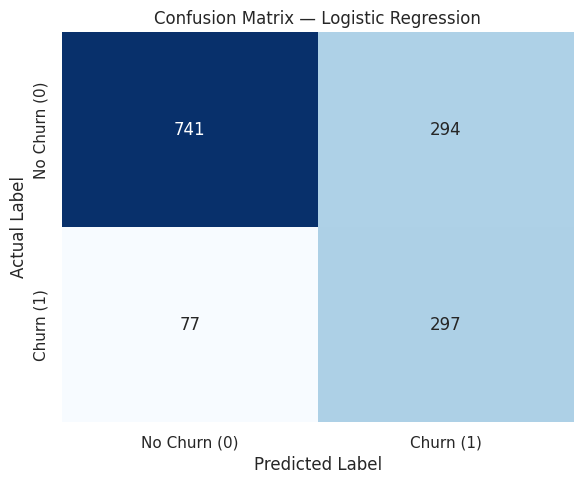

Logistic Regression: TN=741, FP=294, FN=77, TP=297
  -> 77 churners missed entirely; 294 retained customers incorrectly flagged.



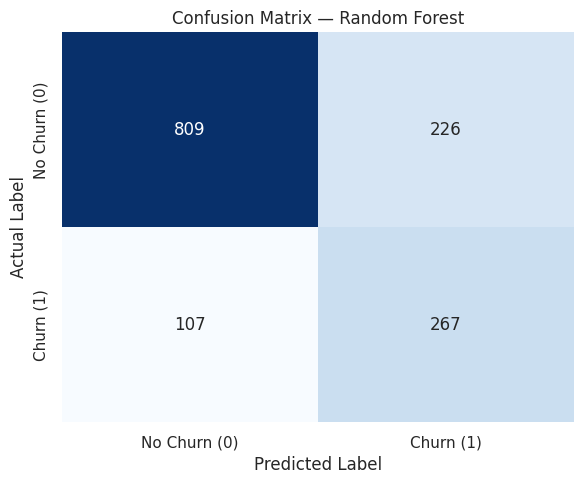

Random Forest: TN=809, FP=226, FN=107, TP=267
  -> 107 churners missed entirely; 226 retained customers incorrectly flagged.



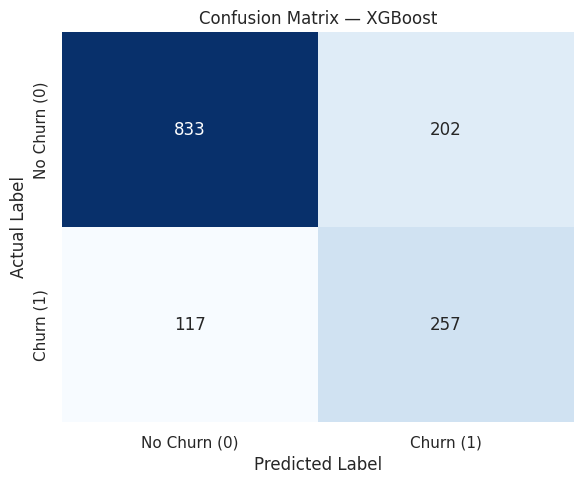

XGBoost: TN=833, FP=202, FN=117, TP=257
  -> 117 churners missed entirely; 202 retained customers incorrectly flagged.



In [16]:
for name, tuned in tuned_pipelines.items():
    y_pred = tuned.predict(X_test)
    filename = f"confusion_matrix_{name.lower().replace(' ', '_')}.png"
    fig, cm = ev.plot_confusion_matrix(
        y_test, y_pred, model_name=name, save_path=FIGURES_DIR / filename
    )
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
    print(f"  -> {fn} churners missed entirely; {fp} retained customers incorrectly flagged.\n")


## 14. ROC Curves

All three models on one axis. The AUC values in the legend are **computed inside the plotting
function** from the actual predicted probabilities — they are not passed in or hardcoded.

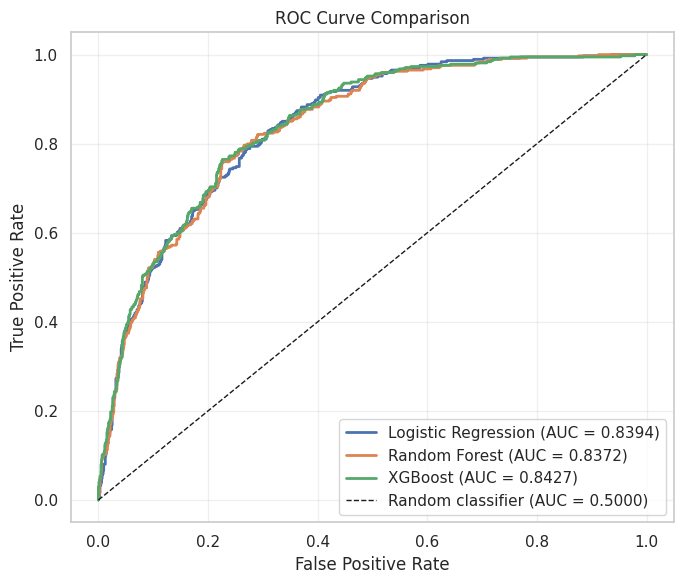

In [17]:
fig = ev.plot_roc_curves(model_probas, save_path=FIGURES_DIR / "roc_curve_comparison.png")
plt.show()


## 15. Threshold Analysis

By default a classifier labels a customer "churn" when predicted probability >= 0.50. There is
nothing sacred about 0.50 — it is just a default, and for imbalanced problems where recall
matters, a lower cutoff is often justified.

**Doing this correctly:** we must not pick a threshold using the test set — that would be tuning
on test data and would invalidate the final metrics. Instead we generate **out-of-fold
cross-validated predictions on the training set** via `cross_val_predict`. Each training row gets
a probability from a model that never saw that row during its own fitting, so these probabilities
are an honest stand-in for unseen data.

In [18]:
# First, select the final model per the pre-declared criterion (see Section 17 for full reasoning)
SELECTION_METRIC = "roc_auc_mean"
best_row = max(tuned_cv_results, key=lambda r: r[SELECTION_METRIC])
selected_model_name = best_row["model"]
selected_pipeline = tuned_pipelines[selected_model_name]

print(f"Model selected by {SELECTION_METRIC} (CV on training data): {selected_model_name}")
print(f"  {SELECTION_METRIC} = {best_row[SELECTION_METRIC]:.4f}")


Model selected by roc_auc_mean (CV on training data): XGBoost
  roc_auc_mean = 0.8470


In [19]:
# Out-of-fold probabilities on TRAINING data only
oof_proba = cross_val_predict(
    selected_pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

threshold_df = ev.threshold_analysis(y_train, oof_proba, thresholds=(0.30, 0.40, 0.50, 0.60, 0.70))
threshold_df.round(4)


,threshold,precision,recall,f1,tn,fp,fn,tp
0,0.3,0.4914,0.8415,0.6205,2837,1302,237,1258
1,0.4,0.5381,0.7645,0.6317,3158,981,352,1143
2,0.5,0.5953,0.6916,0.6399,3436,703,461,1034
3,0.6,0.6381,0.5826,0.6091,3645,494,624,871
4,0.7,0.6937,0.4515,0.5470,3841,298,820,675


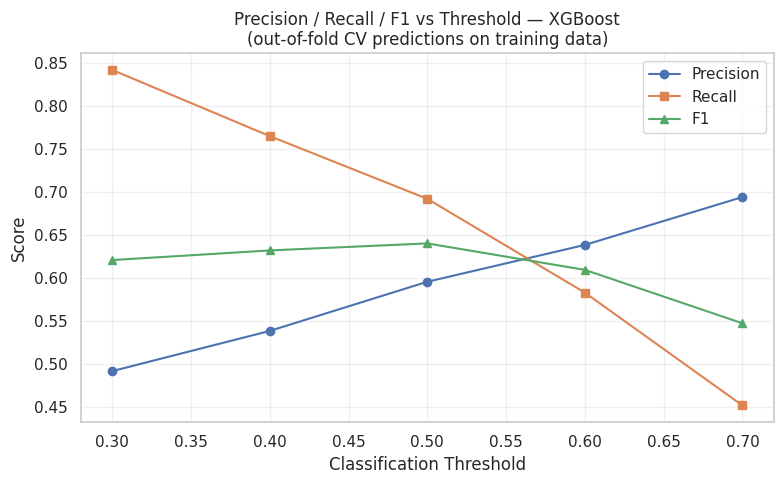

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(threshold_df["threshold"], threshold_df["precision"], marker="o", label="Precision")
ax.plot(threshold_df["threshold"], threshold_df["recall"], marker="s", label="Recall")
ax.plot(threshold_df["threshold"], threshold_df["f1"], marker="^", label="F1")
ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Score")
ax.set_title(f"Precision / Recall / F1 vs Threshold — {selected_model_name}\n(out-of-fold CV predictions on training data)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "threshold_analysis.png", dpi=150)
plt.show()


In [21]:
best_f1_row = threshold_df.loc[threshold_df["f1"].idxmax()]
selected_threshold = float(best_f1_row["threshold"])

print(f"Threshold with highest out-of-fold F1: {selected_threshold:.2f}")
print(f"  precision={best_f1_row['precision']:.4f}, recall={best_f1_row['recall']:.4f}, f1={best_f1_row['f1']:.4f}")
print()
print("Trade-off note: this threshold maximises F1, which balances precision and recall.")
print("A business prioritising recall (catching more churners, accepting more wasted offers)")
print("could justify a lower threshold - the table above quantifies exactly what that costs")
print("in precision at each step. The choice is a business decision, not purely a statistical one.")


Threshold with highest out-of-fold F1: 0.50
  precision=0.5953, recall=0.6916, f1=0.6399

Trade-off note: this threshold maximises F1, which balances precision and recall.
A business prioritising recall (catching more churners, accepting more wasted offers)
could justify a lower threshold - the table above quantifies exactly what that costs
in precision at each step. The choice is a business decision, not purely a statistical one.


## 16. Model Comparison

The combined table below places baseline CV, tuned CV, and final test results side by side. All
values are computed; none are entered by hand.

In [22]:
rows = []
for base, tuned, test in zip(baseline_cv_results, tuned_cv_results, test_results):
    assert base["model"] == tuned["model"] == test["model"]
    rows.append({
        "Model": base["model"],
        "CV Accuracy": round(tuned["accuracy_mean"], 4),
        "CV Precision": round(tuned["precision_mean"], 4),
        "CV Recall": round(tuned["recall_mean"], 4),
        "CV F1": round(tuned["f1_mean"], 4),
        "CV ROC-AUC": round(tuned["roc_auc_mean"], 4),
        "Test Accuracy": round(test["accuracy"], 4),
        "Test Precision": round(test["precision"], 4),
        "Test Recall": round(test["recall"], 4),
        "Test F1": round(test["f1"], 4),
        "Test ROC-AUC": round(test["roc_auc"], 4),
    })

final_comparison_df = pd.DataFrame(rows)
final_comparison_df


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Logistic Regression,0.7556,0.5265,0.7860,0.6304,0.8451,0.7367,0.5025,0.7941,0.6155,0.8394
1,Random Forest,0.7774,0.5626,0.7284,0.6346,0.8433,0.7637,0.5416,0.7139,0.6159,0.8372
2,XGBoost,0.7934,0.5954,0.6916,0.6398,0.8470,0.7736,0.5599,0.6872,0.6170,0.8427


In [23]:
# Also show the baseline-vs-tuned CV picture explicitly, so the three stages stay distinguishable
stages = []
for base, tuned in zip(baseline_cv_results, tuned_cv_results):
    stages.append({"Model": base["model"], "Stage": "Baseline CV", "ROC-AUC": round(base["roc_auc_mean"], 4)})
    stages.append({"Model": tuned["model"], "Stage": "Tuned CV", "ROC-AUC": round(tuned["roc_auc_mean"], 4)})
for test in test_results:
    stages.append({"Model": test["model"], "Stage": "Final Test", "ROC-AUC": round(test["roc_auc"], 4)})

pd.DataFrame(stages).pivot(index="Model", columns="Stage", values="ROC-AUC")


Stage,Baseline CV,Final Test,Tuned CV
Model,,,
Logistic Regression,0.8450,0.8394,0.8451
Random Forest,0.8386,0.8372,0.8433
XGBoost,0.8319,0.8427,0.8470


## 17. Final Model Selection

The criterion was fixed in Section 1 **before** any results were seen: highest mean CV ROC-AUC on
the training set. We apply it mechanically below, rather than reading the test results and
choosing a winner retrospectively.

Read the computed tables above for the actual figures. Some honest framing to apply when
interpreting them:

- Differences smaller than the fold-to-fold standard deviation are **not** strong evidence of
  superiority. Check the `roc_auc_std` column before treating a gap as real.
- A model can lead on ROC-AUC while trailing on recall, or vice versa. Those are different
  questions, and which one matters depends on the business objective.
- **XGBoost is not assumed to win.** It may or may not; the criterion decides.

**Practical trade-offs among the three, independent of the scores:**
- *Logistic Regression* — simplest and most interpretable; coefficients are directly explainable
  to non-technical stakeholders. Cheapest to train, serve, and audit.
- *Random Forest* — captures non-linearities and interactions without tuning effort; robust and
  hard to break, but a larger artifact and less directly interpretable.
- *XGBoost* — typically strong on tabular data, but has the most hyperparameters, the highest
  overfitting risk if over-tuned, and needs a tool like SHAP to explain its predictions.

In [24]:
print(f"Selection criterion: highest {SELECTION_METRIC} in 5-fold stratified CV on training data")
print()
for r in sorted(tuned_cv_results, key=lambda r: r[SELECTION_METRIC], reverse=True):
    print(f"  {r['model']:<22} {SELECTION_METRIC} = {r[SELECTION_METRIC]:.4f} "
          f"(std across folds = {r['roc_auc_std']:.4f})")

print()
print(f"=> Selected model: {selected_model_name}")

# Check whether the lead is larger than fold-to-fold variation
sorted_results = sorted(tuned_cv_results, key=lambda r: r[SELECTION_METRIC], reverse=True)
if len(sorted_results) > 1:
    lead = sorted_results[0][SELECTION_METRIC] - sorted_results[1][SELECTION_METRIC]
    std_of_winner = sorted_results[0]["roc_auc_std"]
    print(f"   Lead over 2nd place: {lead:.4f} | winner's fold std: {std_of_winner:.4f}")
    if lead < std_of_winner:
        print("   NOTE: the lead is SMALLER than the winner's fold-to-fold std. The models are")
        print("   close; this selection should be read as 'no clear separation', not dominance.")
    else:
        print("   The lead exceeds the winner's fold-to-fold std.")


Selection criterion: highest roc_auc_mean in 5-fold stratified CV on training data

  XGBoost                roc_auc_mean = 0.8470 (std across folds = 0.0102)
  Logistic Regression    roc_auc_mean = 0.8451 (std across folds = 0.0133)
  Random Forest          roc_auc_mean = 0.8433 (std across folds = 0.0086)

=> Selected model: XGBoost
   Lead over 2nd place: 0.0020 | winner's fold std: 0.0102
   NOTE: the lead is SMALLER than the winner's fold-to-fold std. The models are
   close; this selection should be read as 'no clear separation', not dominance.


## 18. Save Final Model

We save the **complete fitted pipeline** (preprocessing + SMOTE configuration + classifier) with
`joblib`. Saving the whole pipeline — rather than just the classifier — means the Streamlit app
can feed in raw, human-readable customer fields and the identical preprocessing will be applied
automatically. This eliminates train/serve skew, a very common source of production bugs.

Note: the SMOTE step travels with the pipeline as configuration, but because this is an `imblearn`
pipeline, it is automatically skipped at prediction time.

In [25]:
MODEL_PATH = MODELS_DIR / "churn_model.pkl"
METADATA_PATH = MODELS_DIR / "model_metadata.json"

# Ensure the selected pipeline is fit on the full training data
selected_pipeline.fit(X_train, y_train)
joblib.dump(selected_pipeline, MODEL_PATH)
print(f"Saved fitted pipeline to: {MODEL_PATH}")

fitted_preprocessor = selected_pipeline.named_steps["preprocessor"]
transformed_names = ev.get_transformed_feature_names(fitted_preprocessor)

selected_test_metrics = next(r for r in test_results if r["model"] == selected_model_name)

metadata = {
    "model_name": selected_model_name,
    "selection_metric": SELECTION_METRIC,
    "selection_criterion": (
        "Highest mean ROC-AUC across stratified 5-fold cross-validation on the training set. "
        "Declared before results were observed; test set not involved in selection."
    ),
    "random_state": RANDOM_STATE,
    "cv_n_splits": N_SPLITS,
    "selected_threshold": selected_threshold,
    "threshold_selection_method": "Maximised F1 over out-of-fold CV predictions on the training set.",
    "original_feature_names": list(X_train.columns),
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "n_transformed_features": len(transformed_names),
    "best_hyperparameters": {k: str(v) for k, v in best_params_per_model[selected_model_name].items()},
    "tuned_cv_results": tuned_cv_results,
    "test_results_default_threshold": test_results,
    "selected_model_test_metrics": selected_test_metrics,
}

with open(METADATA_PATH, "w") as f:
    json.dump(metadata, f, indent=2, default=str)
print(f"Saved metadata to: {METADATA_PATH}")


Saved fitted pipeline to: /path/to/customer-churn-prediction/models/churn_model.pkl
Saved metadata to: /path/to/customer-churn-prediction/models/model_metadata.json


In [26]:
# Verify the saved artifact round-trips correctly
reloaded = joblib.load(MODEL_PATH)
print("Reloaded pipeline steps:", [n for n, _ in reloaded.steps])

sample = X_test.head(5)
print("\nPredictions on 5 test rows:", reloaded.predict(sample).tolist())
print("Probabilities:            ", np.round(reloaded.predict_proba(sample)[:, 1], 4).tolist())

# Confirm reloaded model reproduces the same test metrics (no corruption on save/load)
reloaded_proba = reloaded.predict_proba(X_test)[:, 1]
reloaded_pred = reloaded.predict(X_test)
reloaded_metrics = ev.calculate_classification_metrics(y_test, reloaded_pred, reloaded_proba, selected_model_name)
print(f"\nReloaded model test ROC-AUC: {reloaded_metrics['roc_auc']:.4f}")
print(f"Original model test ROC-AUC: {selected_test_metrics['roc_auc']:.4f}")
assert np.isclose(reloaded_metrics["roc_auc"], selected_test_metrics["roc_auc"]), "Saved model does not match!"
print("Saved model verified: metrics match exactly.")


Reloaded pipeline steps: ['preprocessor', 'smote', 'classifier']

Predictions on 5 test rows: [0, 1, 0, 0, 0]
Probabilities:             [0.035999998450279236, 0.7889999747276306, 0.0575999990105629, 0.38909998536109924, 0.02410000003874302]

Reloaded model test ROC-AUC: 0.8427
Original model test ROC-AUC: 0.8427
Saved model verified: metrics match exactly.


### Feature name mapping (preparation for SHAP)

SHAP needs to label its plots with meaningful feature names. Because our `ColumnTransformer`
one-hot encodes categorical columns, the transformed matrix has more columns than the original
dataframe. `get_feature_names_out()` gives us the transformed names, and the helper below maps
each one back to the original column it came from.

In [27]:
feature_mapping = ev.map_transformed_to_original(
    transformed_names, numerical_features, categorical_features
)
print(f"Original features: {X_train.shape[1]} -> Transformed features: {len(transformed_names)}")
feature_mapping.head(20)


Original features: 19 -> Transformed features: 45


,transformed_feature,original_feature,type,category
0,num__SeniorCitizen,SeniorCitizen,numerical,NaN
1,num__tenure,tenure,numerical,NaN
2,num__MonthlyCharges,MonthlyCharges,numerical,NaN
3,num__TotalCharges,TotalCharges,numerical,NaN
4,cat__gender_Female,gender,categorical (one-hot),Female
5,cat__gender_Male,gender,categorical (one-hot),Male
6,cat__Partner_No,Partner,categorical (one-hot),No
7,cat__Partner_Yes,Partner,categorical (one-hot),Yes
8,cat__Dependents_No,Dependents,categorical (one-hot),No
9,cat__Dependents_Yes,Dependents,categorical (one-hot),Yes


In [28]:
# Verify the transformed matrix width matches the number of names (SHAP compatibility check)
X_train_transformed = fitted_preprocessor.transform(X_train)
print(f"Transformed matrix shape: {X_train_transformed.shape}")
print(f"Number of feature names:  {len(transformed_names)}")
assert X_train_transformed.shape[1] == len(transformed_names), "Feature name/column count mismatch!"
print("Feature names align with transformed matrix - ready for SHAP in Step 5.")


Transformed matrix shape: (5634, 45)
Number of feature names:  45
Feature names align with transformed matrix - ready for SHAP in Step 5.


## 19. Summary

This notebook (see executed outputs above for exact values):
- Reused the validated preprocessing architecture from `src/data_preprocessing.py` without
  redesigning it.
- Built three identical-architecture pipelines (preprocessing → SMOTE → classifier).
- Ran stratified 5-fold CV on training data only, with SMOTE inside each fold.
- Tuned all three models with `RandomizedSearchCV` over the full pipeline, on training data only.
- Selected the final model using a criterion declared in advance (highest CV ROC-AUC).
- Chose a classification threshold from out-of-fold training predictions, never the test set.
- Evaluated on the sealed test set exactly once, reporting all required metrics and confusion
  matrix components.
- Saved the complete fitted pipeline and metadata, and verified the artifact reloads and
  reproduces identical metrics.

**Known limitations:**
- This is a static, single-snapshot dataset with no time dimension; real churn prediction would
  use time-based validation to avoid learning from the future.
- The dataset is a well-known public benchmark, not this business's own customers — the patterns
  may not transfer.
- No cost-sensitive analysis was performed; the optimal threshold in practice depends on the real
  ratio between retention-offer cost and customer lifetime value, which we do not have.
- `RandomizedSearchCV` explores only a sample of the hyperparameter space by design.

## 20. Next Step: SHAP Explainability

Step 5 will load the saved pipeline and use SHAP to explain the selected model's predictions:
global feature importance (which factors drive churn overall), summary/beeswarm plots showing
direction of effect, and individual force plots explaining single-customer predictions — which
feeds directly into the Streamlit app, where a retention agent needs to see *why* a customer was
flagged, not just the probability.